**SKIN DISORDER PREDICTION**

**1. Problem Statement**

Build a multi-class classification model to predict the type of skin disease using clinical and histopathological features.

Goal: Help doctors identify disease at an early stage.

**2. Dataset Understanding**



*   Instances: ~366 patients
*   Features: 34 attributes

*   Target: Class (Skin disease type)
*   Type: Multi-class classification (6 diseases)



**Disease Classes :**

1. Psoriasis

2. Seborrheic dermatitis

3. Lichen planus

4. Pityriasis rosea

5. Chronic dermatitis

6. Pityriasis rubra pilaris

**Import libraries**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

In [ ]:
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import *
from sklearn.impute import SimpleImputer

In [ ]:
skin_dis = pd.read_csv("/content/dataset_35_dermatology (1).csv")

In [ ]:
skin_dis

,erythema,scaling,definite_borders,itching,koebner_phenomenon,polygonal_papules,follicular_papules,oral_mucosal_involvement,knee_and_elbow_involvement,scalp_involvement,...,disappearance_of_the_granular_layer,vacuolisation_and_damage_of_basal_layer,spongiosis,saw-tooth_appearance_of_retes,follicular_horn_plug,perifollicular_parakeratosis,inflammatory_monoluclear_inflitrate,band-like_infiltrate,Age,class
0,2,2,0,3,0,0,0,0,1,0,...,0,0,3,0,0,0,1,0,55,2
1,3,3,3,2,1,0,0,0,1,1,...,0,0,0,0,0,0,1,0,8,1
2,2,1,2,3,1,3,0,3,0,0,...,0,2,3,2,0,0,2,3,26,3
3,2,2,2,0,0,0,0,0,3,2,...,3,0,0,0,0,0,3,0,40,1
4,2,3,2,2,2,2,0,2,0,0,...,2,3,2,3,0,0,2,3,45,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
361,2,1,1,0,1,0,0,0,0,0,...,0,0,1,0,0,0,2,0,25,4
362,3,2,1,0,1,0,0,0,0,0,...,1,0,1,0,0,0,2,0,36,4
363,3,2,2,2,3,2,0,2,0,0,...,0,3,0,3,0,0,2,3,28,3
364,2,1,3,1,2,3,0,2,0,0,...,0,2,0,1,0,0,2,3,50,3


In [ ]:
# First five rows and shape
skin_dis.head()
skin_dis.shape

(366, 36)

In [ ]:
# Last five rows
skin_dis.tail()

,erythema,scaling,definite_borders,itching,koebner_phenomenon,polygonal_papules,follicular_papules,oral_mucosal_involvement,knee_and_elbow_involvement,scalp_involvement,...,disappearance_of_the_granular_layer,vacuolisation_and_damage_of_basal_layer,spongiosis,saw-tooth_appearance_of_retes,follicular_horn_plug,perifollicular_parakeratosis,inflammatory_monoluclear_inflitrate,band-like_infiltrate,Age,class
361,2,1,1,0,1,0,0,0,0,0,...,0,0,1,0,0,0,2,0,25,4
362,3,2,1,0,1,0,0,0,0,0,...,1,0,1,0,0,0,2,0,36,4
363,3,2,2,2,3,2,0,2,0,0,...,0,3,0,3,0,0,2,3,28,3
364,2,1,3,1,2,3,0,2,0,0,...,0,2,0,1,0,0,2,3,50,3
365,3,2,2,0,0,0,0,0,3,3,...,2,0,0,0,0,0,3,0,35,1


In [ ]:
# Summary of entire dataframe
skin_dis.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 366 entries, 0 to 365
Data columns (total 35 columns):
 #   Column                                    Non-Null Count  Dtype 
---  ------                                    --------------  ----- 
 0   erythema                                  366 non-null    int64 
 1   scaling                                   366 non-null    int64 
 2   definite_borders                          366 non-null    int64 
 3   itching                                   366 non-null    int64 
 4   koebner_phenomenon                        366 non-null    int64 
 5   polygonal_papules                         366 non-null    int64 
 6   follicular_papules                        366 non-null    int64 
 7   oral_mucosal_involvement                  366 non-null    int64 
 8   knee_and_elbow_involvement                366 non-null    int64 
 9   scalp_involvement                         366 non-null    int64 
 10  family_history                            366 non-

In [ ]:
# Statistical summary of numerical column
skin_dis.describe()

,erythema,scaling,definite_borders,itching,koebner_phenomenon,polygonal_papules,follicular_papules,oral_mucosal_involvement,knee_and_elbow_involvement,scalp_involvement,...,focal_hypergranulosis,disappearance_of_the_granular_layer,vacuolisation_and_damage_of_basal_layer,spongiosis,saw-tooth_appearance_of_retes,follicular_horn_plug,perifollicular_parakeratosis,inflammatory_monoluclear_inflitrate,band-like_infiltrate,class
count,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,...,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000
mean,2.068306,1.795082,1.549180,1.366120,0.633880,0.448087,0.166667,0.377049,0.614754,0.519126,...,0.393443,0.464481,0.456284,0.953552,0.453552,0.103825,0.114754,1.866120,0.554645,2.803279
std,0.664753,0.701527,0.907525,1.138299,0.908016,0.957327,0.570588,0.834147,0.982979,0.905639,...,0.849406,0.864899,0.954873,1.130172,0.954744,0.450433,0.488723,0.726108,1.105908,1.597803
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,2.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,1.000000
50%,2.000000,2.000000,2.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,0.000000,3.000000
75%,2.000000,2.000000,2.000000,2.000000,1.000000,0.000000,0.000000,0.000000,1.000000,1.000000,...,0.000000,1.000000,0.000000,2.000000,0.000000,0.000000,0.000000,2.000000,0.000000,4.000000
max,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,...,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,6.000000


**EDA**

In [ ]:
# We convert Map Class Numbers → Disease Names
disease_map = {
    1: "Psoriasis",
    2: "Seborrheic Dermatitis",
    3: "Lichen Planus",
    4: "Pityriasis Rosea",
    5: "Chronic Dermatitis",
    6: "Pityriasis Rubra Pilaris"
}

skin_dis["Disease_Name"] = skin_dis["class"].map(disease_map)

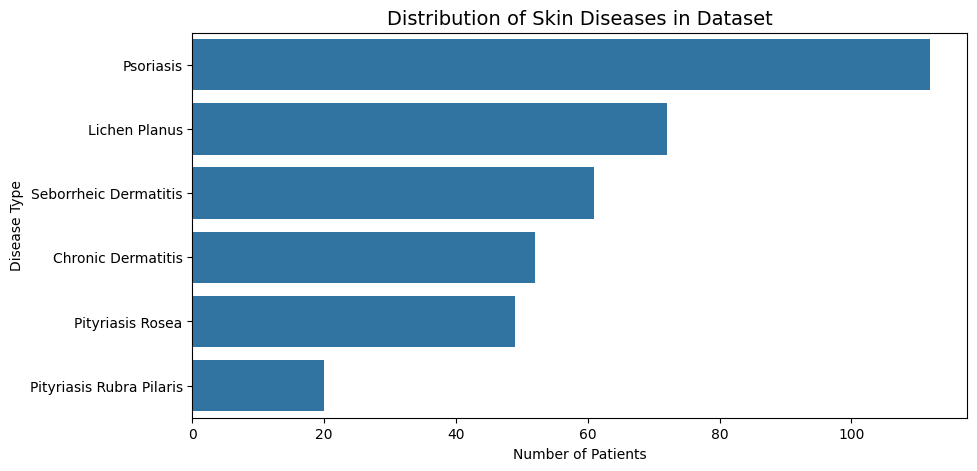

In [ ]:
# Class Distribution (Target Variable)
plt.figure(figsize=(10,5))
sns.countplot(y="Disease_Name", data=skin_dis, order=skin_dis["Disease_Name"].value_counts().index)
plt.title("Distribution of Skin Diseases in Dataset", fontsize=14)
plt.xlabel("Number of Patients")
plt.ylabel("Disease Type")
plt.show()

The class distribution analysis shows that the dataset contains six types of erythemato-squamous skin diseases with a relatively balanced number of patient records across most categories. Psoriasis and Chronic Dermatitis appear slightly more frequently, while Pityriasis Rubra Pilaris has comparatively fewer cases. However, no extreme imbalance is observed.

This balanced structure is beneficial for multi-class machine learning because the model can learn patterns for each disease without being overly biased toward one dominant class. It also ensures that evaluation metrics such as accuracy, precision, and recall provide a fair representation of model performance across all disease types.

From a medical perspective, the distribution reflects real-world diagnostic diversity, where multiple skin disorders share overlapping symptoms but occur at varying frequencies. Therefore, careful model evaluation using class-wise metrics remains important to ensure reliable predictions for less frequent diseases.

In [ ]:
distribution = skin_dis["Disease_Name"].value_counts().reset_index()
distribution.columns = ["Disease", "Patient_Count"]
distribution

,Disease,Patient_Count
0,Psoriasis,112
1,Lichen Planus,72
2,Seborrheic Dermatitis,61
3,Chronic Dermatitis,52
4,Pityriasis Rosea,49
5,Pityriasis Rubra Pilaris,20


Insight

Dataset is fairly balanced

Good for multi-class modeling

No extreme imbalance issue

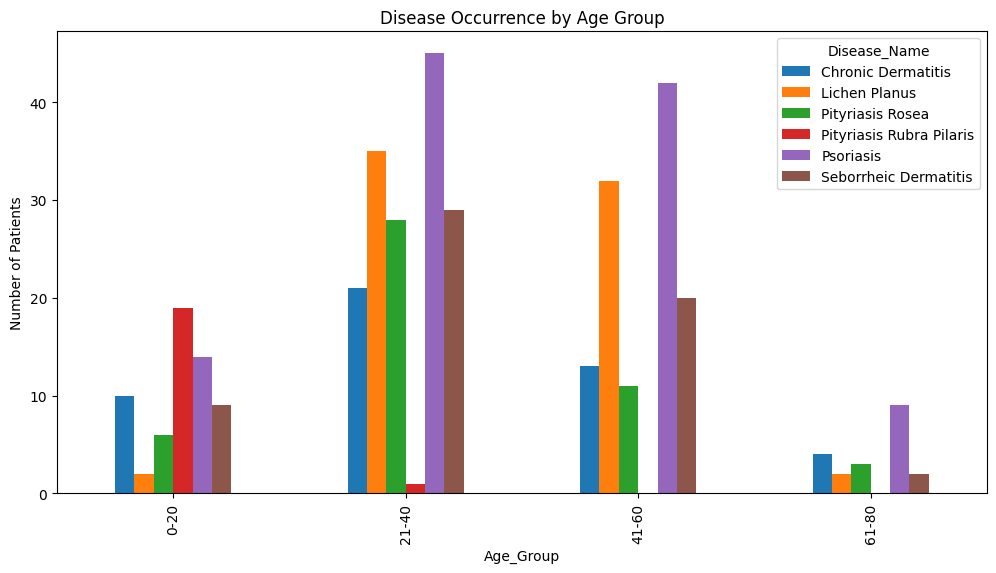

In [ ]:
# Age Group Analysis

bins = [0, 20, 40, 60, 80]
labels = ["0-20", "21-40", "41-60", "61-80"]

skin_dis["Age_Group"] = pd.cut(skin_dis["age"], bins=bins, labels=labels)

pd.crosstab(skin_dis["Age_Group"], skin_dis["Disease_Name"]).plot(kind='bar', figsize=(12,6))
plt.title("Disease Occurrence by Age Group")
plt.ylabel("Number of Patients")
plt.show()

The age group analysis indicates that skin disorders are distributed across all age categories, but certain diseases show noticeable tendencies. Pityriasis Rosea and Seborrheic Dermatitis appear more frequently among younger individuals, whereas Psoriasis and Lichen Planus are more common in middle-aged adults. Chronic Dermatitis is observed across a wider age range, suggesting it is less age-specific.

Although age contributes useful contextual information, the overlap between age groups shows that it cannot independently determine the disease type. Therefore, age should be considered a supporting predictive feature alongside clinical and histopathological indicators rather than a primary diagnostic factor.

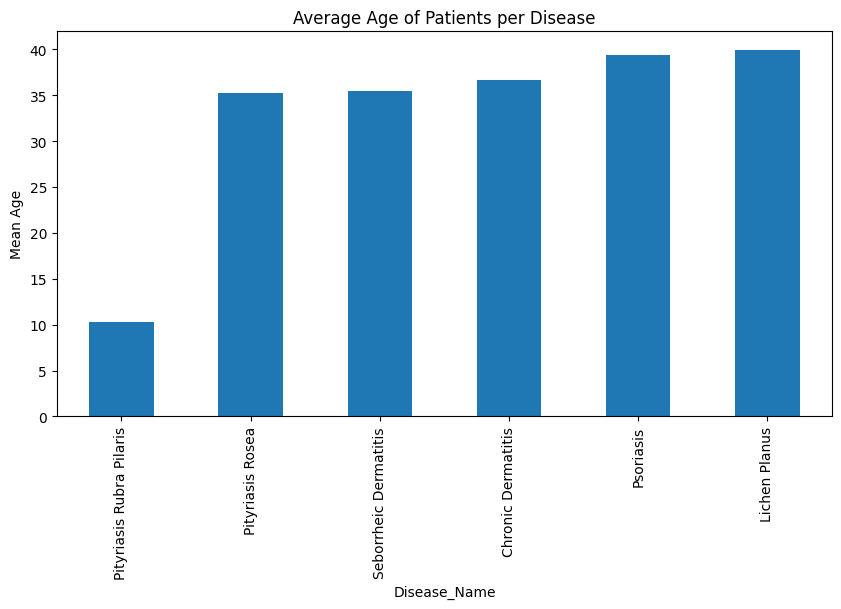

In [ ]:
# Average Age per Disease
age_stats = skin_dis.groupby("Disease_Name")["age"].mean().sort_values()
age_stats.plot(kind='bar', figsize=(10,5))
plt.title("Average Age of Patients per Disease")
plt.ylabel("Mean Age")
plt.show()

This reveals age tendency:

Psoriasis -->	Often middle-aged

Lichen Planus -->	More in adults

Pityriasis Rosea -->	Common in younger people

Chronic Dermatitis -->	Seen across ages

Seborrheic Dermatitis -->	Often younger adults

Pityriasis Rubra Pilaris -->	Rare, varied age



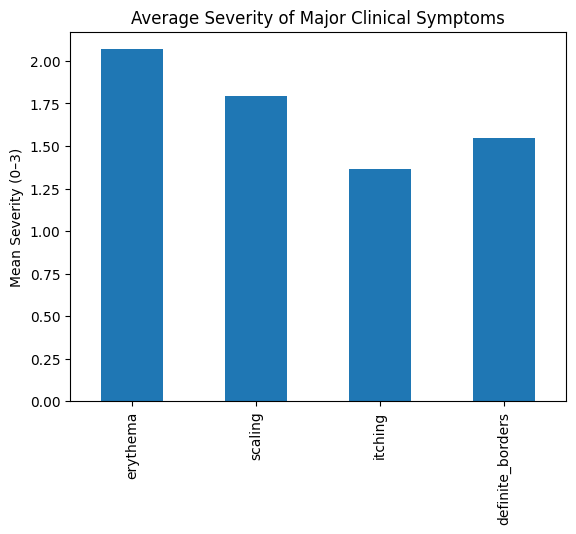

In [ ]:
# Symptom Severity Patterns (eg:major clinical features)

features = ['erythema', 'scaling', 'itching', 'definite_borders']

skin_dis[features].mean().plot(kind='bar')
plt.title("Average Severity of Major Clinical Symptoms")
plt.ylabel("Mean Severity (0–3)")
plt.show()

Scaling & erythema are dominant symptoms

Helps identify inflammatory skin diseases

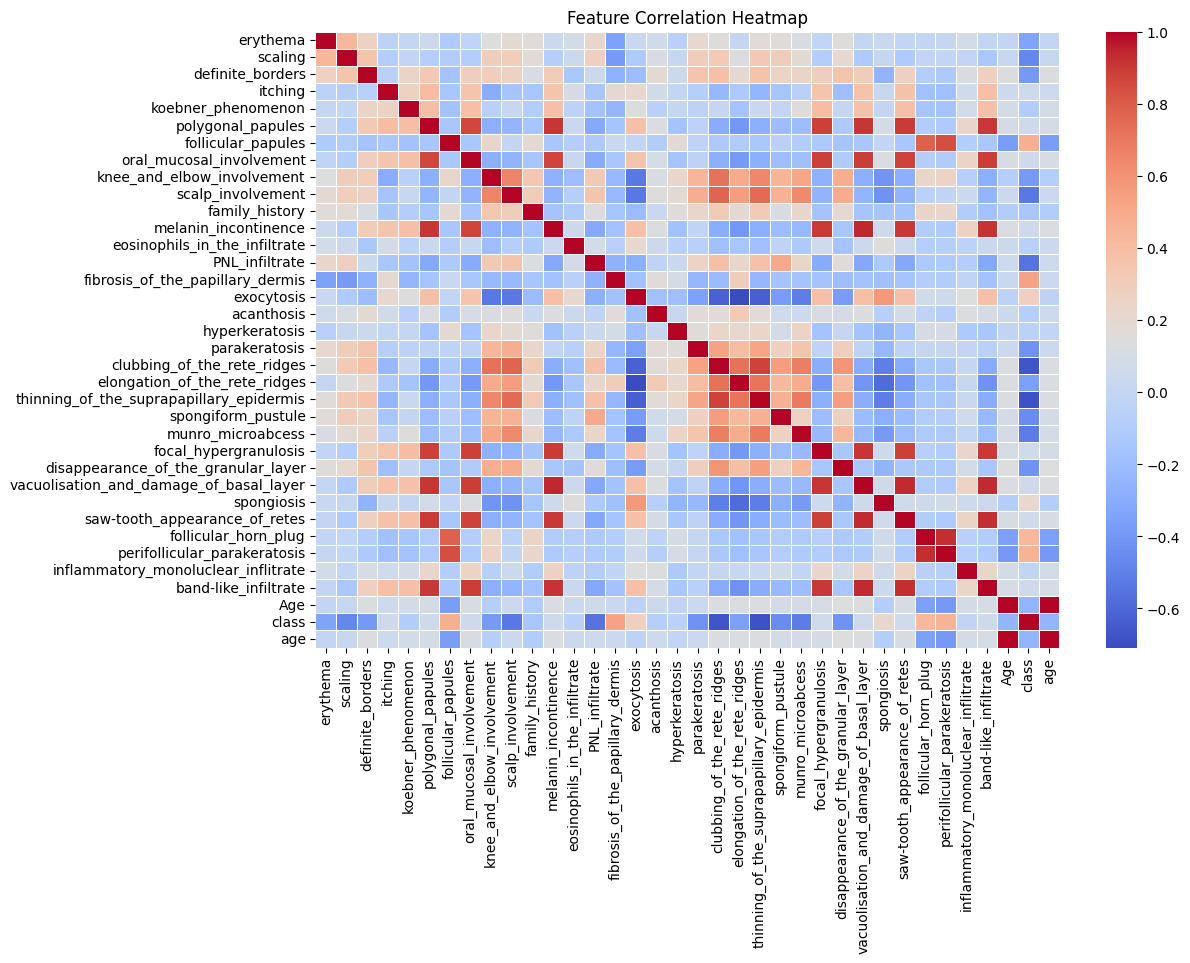

In [ ]:
# Correlation Analysis
plt.figure(figsize=(12,8))
sns.heatmap(skin_dis.corr(), cmap='coolwarm', linewidths=0.5)
plt.title("Feature Correlation Heatmap")
plt.show()

Many histopathological features are correlated

Tree-based models (RF, XGBoost, LightGBM) handle this well

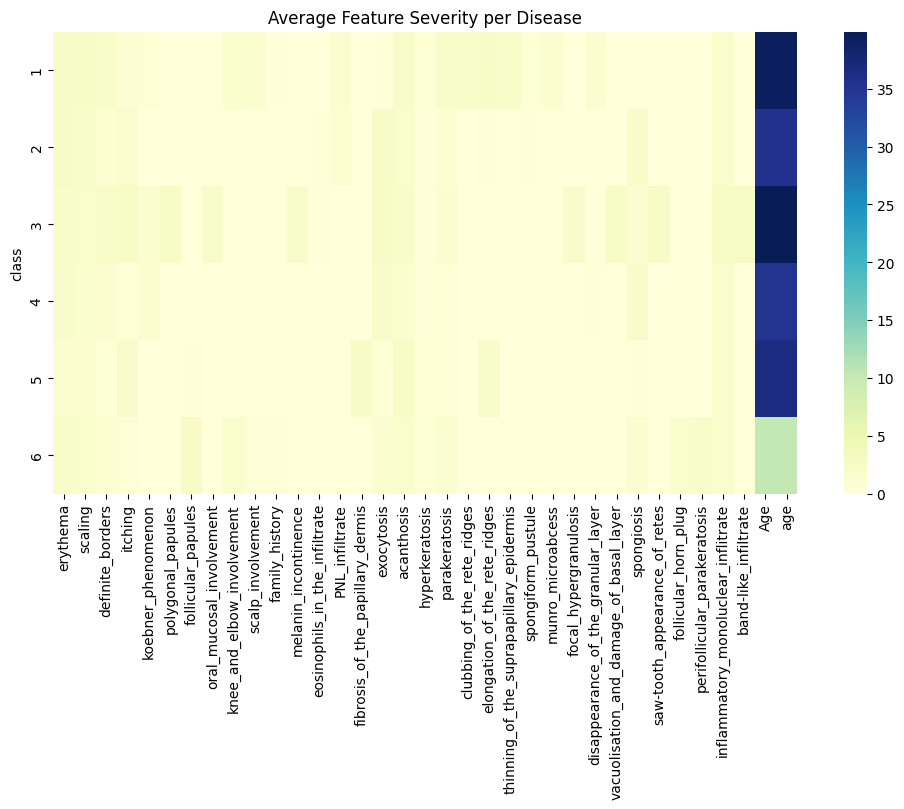

In [ ]:
# Disease-wise Symptom Comparison
grouped = skin_dis.groupby("class").mean()

plt.figure(figsize=(12,6))
sns.heatmap(grouped, cmap="YlGnBu")
plt.title("Average Feature Severity per Disease")
plt.show()

Each disease has a unique pattern:

-Psoriasis → strong scaling & Munro microabscess

-Lichen planus → polygonal papules

-Chronic dermatitis → spongiosis

This confirms dataset suitability for ML.

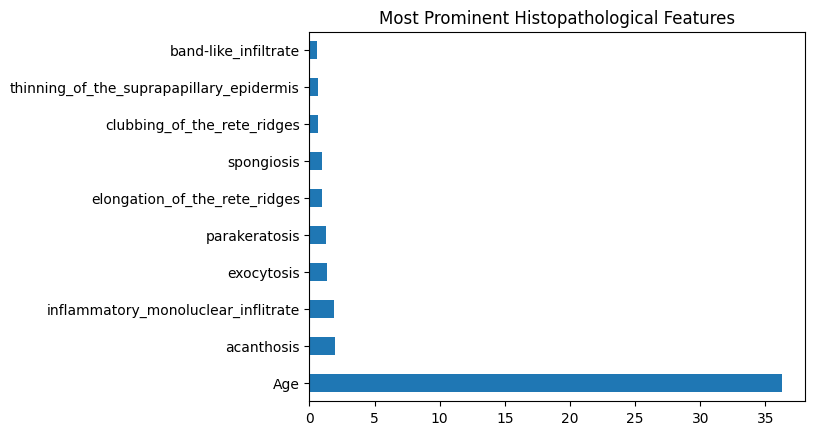

In [ ]:
# Histopathological Feature Importance Trend

histopath = skin_dis.columns[10:34]  # histopath features
skin_dis[histopath].mean().sort_values(ascending=False).head(10).plot(kind='barh')
plt.title("Most Prominent Histopathological Features")
plt.show()

Microscopic features provide strong disease differentiation.

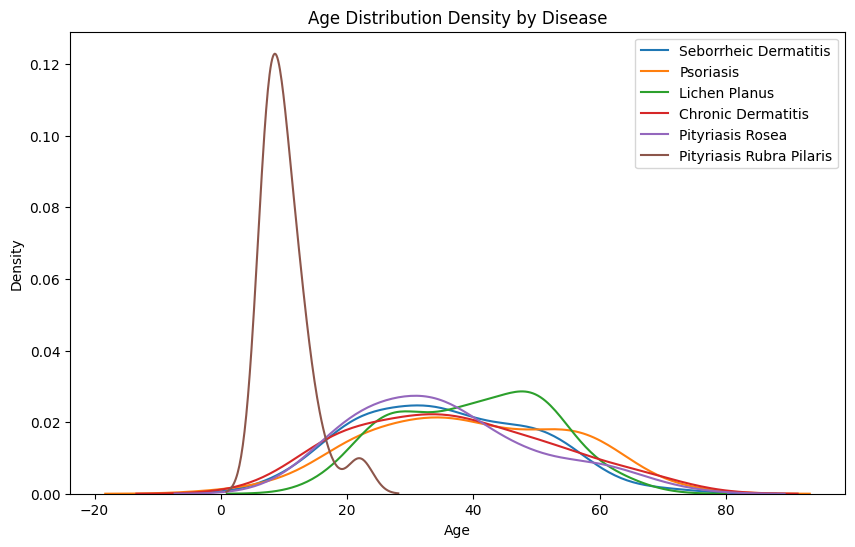

In [ ]:
# Age Distribution Density

plt.figure(figsize=(10,6))

for disease in skin_dis["Disease_Name"].unique():
    sns.kdeplot(skin_dis[skin_dis["Disease_Name"] == disease]["age"], label=disease)

plt.title("Age Distribution Density by Disease")
plt.xlabel("Age")
plt.legend()
plt.show()

Overlapping curves show why ML is needed

Some diseases cluster in specific age ranges

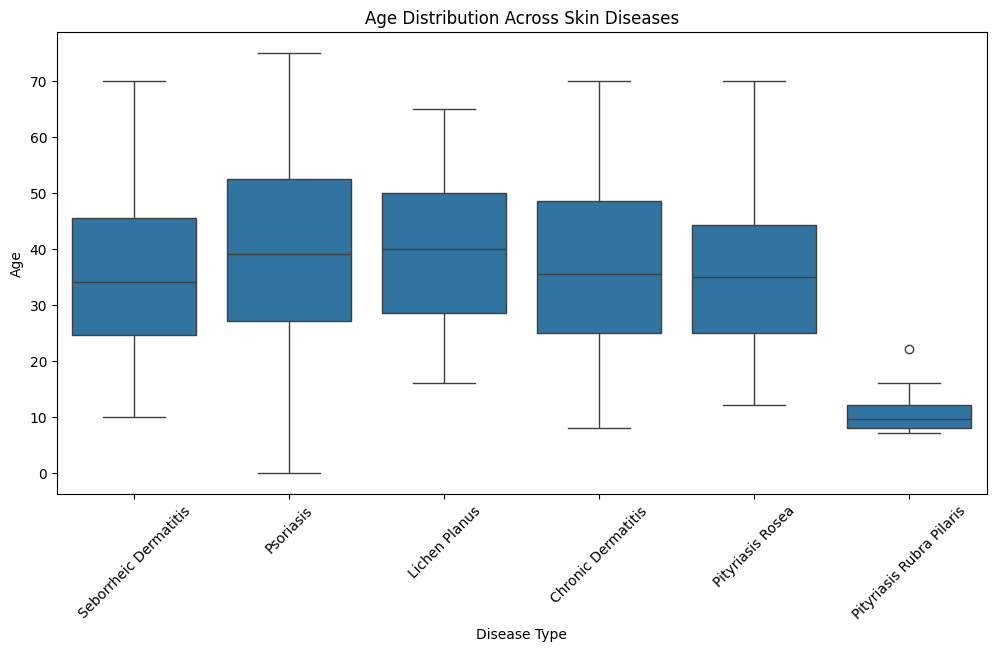

In [ ]:
# Age Distribution by Disease (Boxplot)

plt.figure(figsize=(12,6))
sns.boxplot(x="Disease_Name", y="age", data=skin_dis)
plt.xticks(rotation=45)
plt.title("Age Distribution Across Skin Diseases")
plt.xlabel("Disease Type")
plt.ylabel("Age")
plt.show()

Shows median age, spread, and outliers

Helps identify which disease affects younger vs older patients

**Outlier detection**

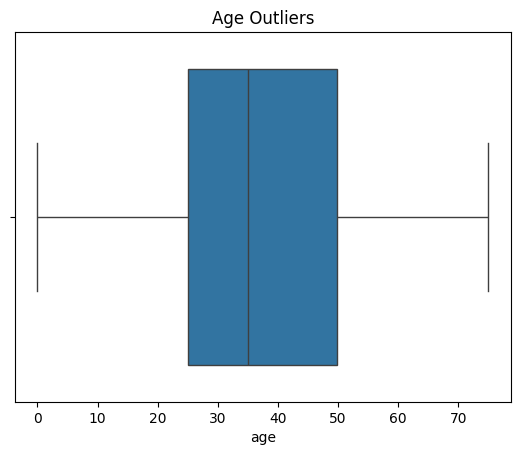

In [ ]:
sns.boxplot(x=skin_dis['age'])
plt.title("Age Outliers")
plt.show()

No extreme outliers → good data consistency.

**DATA CLEANING AND PREPROCESSING**

In [ ]:
skin_dis.isnull().sum()

,0
erythema,0
scaling,0
definite_borders,0
itching,0
koebner_phenomenon,0
polygonal_papules,0
follicular_papules,0
oral_mucosal_involvement,0
knee_and_elbow_involvement,0
scalp_involvement,0


In [ ]:
# Handle Missing Values (Age column usually has '?')
skin_dis['Age'] = pd.to_numeric(skin_dis['Age'], errors='coerce')
skin_dis['Age'].fillna(skin_dis['Age'].median(), inplace=True)

Medical Meaning

Age has missing values → common in hospital records.

We use median imputation later to avoid bias.

In [ ]:
skin_dis.duplicated().sum()

np.int64(0)

In [ ]:
skin_dis.nunique().sort_values()

,0
family_history,2
eosinophils_in_the_infiltrate,3
erythema,4
scaling,4
koebner_phenomenon,4
polygonal_papules,4
definite_borders,4
itching,4
oral_mucosal_involvement,4
follicular_papules,4


In [ ]:
# Convert age
skin_dis['age'] = pd.to_numeric(skin_dis['age'], errors='coerce')

In [ ]:
# Cap Outliers - It is better for medical data
# Instead of deleting patient records, we cap extreme values.

Q1 = skin_dis['age'].quantile(0.25)
Q3 = skin_dis['age'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

skin_dis['age'] = np.where(skin_dis['age'] < lower_bound, lower_bound, skin_dis['age'])
skin_dis['age'] = np.where(skin_dis['age'] > upper_bound, upper_bound, skin_dis['age'])

In [ ]:
# Remove Outliers
skin_dis_no_outliers = skin_dis[(skin_dis['age'] >= lower_bound) & (skin_dis['age'] <= upper_bound)]
print("Before:", skin_dis.shape)
print("After:", skin_dis_no_outliers.shape)

Before: (366, 38)
After: (358, 38)


Feature and target

In [ ]:
X = skin_dis.drop("class", axis=1)
y = skin_dis["class"]

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

In [ ]:
num_features = X.columns  # all are numeric

num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

preprocessor = ColumnTransformer([
    ("num", num_pipeline, num_features)
])